# Linkit SS26: Data Science Grundlagenschulung
### Erstellt von Frederik Eickenbusch

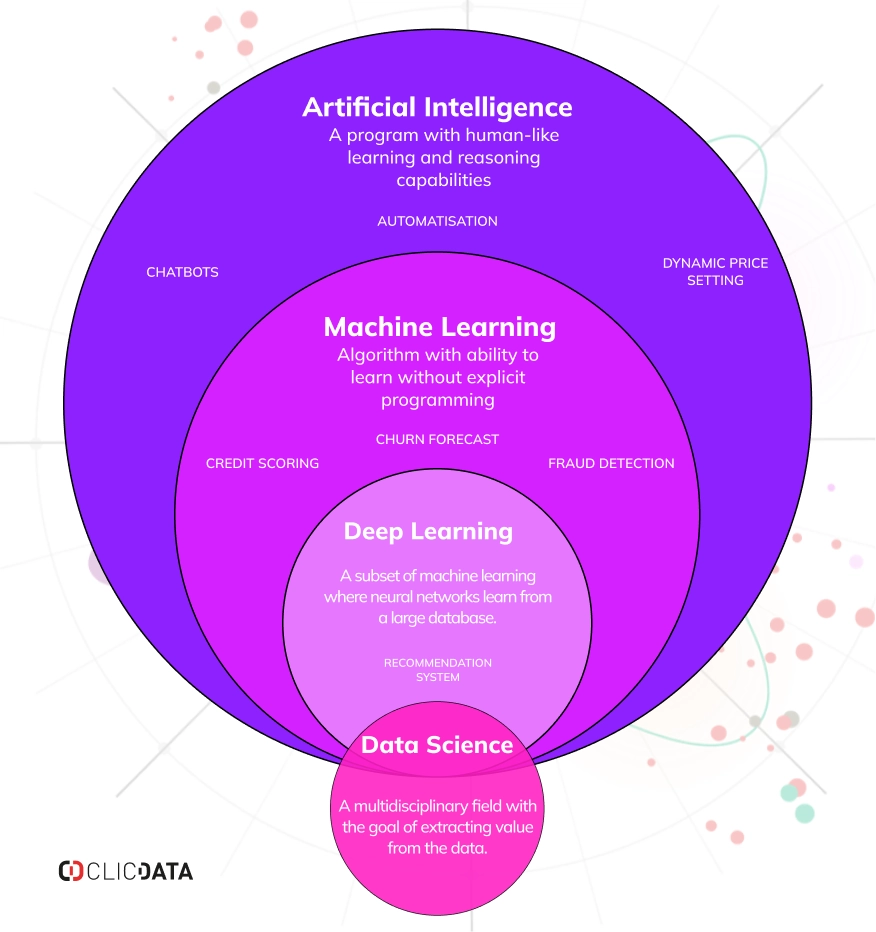

## Cross Industry Standard Process for Data Mining
1. Business Understanding: Was wollen wir kochen? (Das Ziel verstehen)
2. Data Understanding: Welche Zutaten haben wir? (Daten sichten)
3. Data Preparation: Zutaten waschen und schneiden. (Daten bereinigen)
4. Modeling: Das eigentliche Kochen. (Algorithmen anwenden)
5. Evaluation: Schmeckt es? (Ergebnisse prüfen)
6. Deployment: Servieren! (Anwenden)

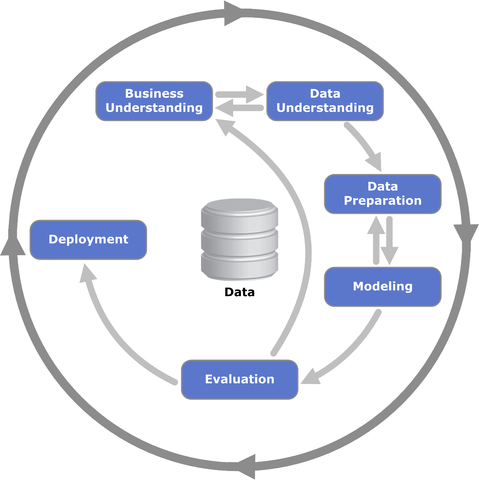

## Warum Python?
- Seit 2021 ist Python die beliebteste Programmiersprache
- Nahezu gesamte ML-Forschung wird in Python durchgeführt
- Alle relevanten Deep-Learning-Module und alle großen Anbieter (OpenAI, Google, Meta) verwenden Python
- Viele Module machen Python für jeden Schritt des Data-Science-Prozesses anwendbar, wie z. B.
Datenmanagement, analytische Verarbeitung und Visualisierungsmodule.

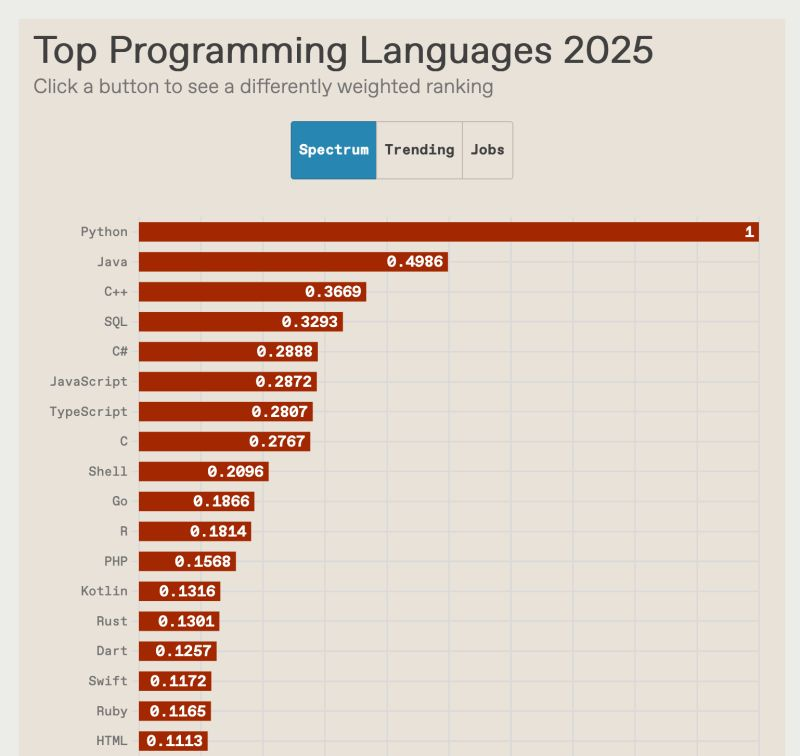

## Datentypen

In [141]:
import sys
import platform

# Ausgabe der vollständigen Version
print("Python-Version:", sys.version)

# Nur Hauptversion
print("Python-Version (nur Zahlen):", platform.python_version())

In [142]:
!pip list

In [143]:
# Integer
a = 5 + 1
print(a, type(a))

In [144]:
# Float
a = 2.5 * 2.5
print(a, type(a))

In [145]:
# String
a = "Linkit"
print(a, type(a))

In [146]:
# Boolean
a = 1
b = 2
print(a > b)
c = True
type(c)

**Wichtiger Unterschied zu pandas Datentypen:**
Numpy Datentypen sind granularer und effizienter (wie C) und damit auch Fehleranfälliger für Overflow etc..
Pandas verwendet intern Numpy arrays, diese verwenden numpy Datentypen und erfordern konsistente Datentypen, im Gegensatz zu Python Listen.

## Was sind Python Module?

- Ein Python Modul ist wie ein Werkzeugkasten mit ähnlichen Funktionalitäten.
- Der Alias (Spitzname): Programmierer sind faul und deshalb geben wir Modulen Spitznamen
- Python Module werden für Datenanalyse, Visualisierung, Maschinelles Lernen und vieles mehr verwendet

In [147]:
import matplotlib.pyplot as plt  # --> Wollen wir jedesmal wenn wir dieses Modul benutzen "matplotlib.pyplot" ausschreiben?

## Einen fehlerhaften Import korrigieren

Wir wollen pandas importieren, ein Modul, mit dem wir Daten laden, filtern, transformieren

Der Standard-Alias für pandas ist pd

In [148]:
import pandas as pd
import seaborn as sns

# Titanic Datensatz

**Datensatz ursprünglich von:** [Kaggle](https://www.kaggle.com/datasets/yasserh/titanic-dataset/data)

Ohne Konto verfügbar in diesem GitHub Repo [Link](https://raw.githubusercontent.com/nrfnm/linkit-grundlagenschulung/refs/heads/main/Titanic-Dataset.csv)

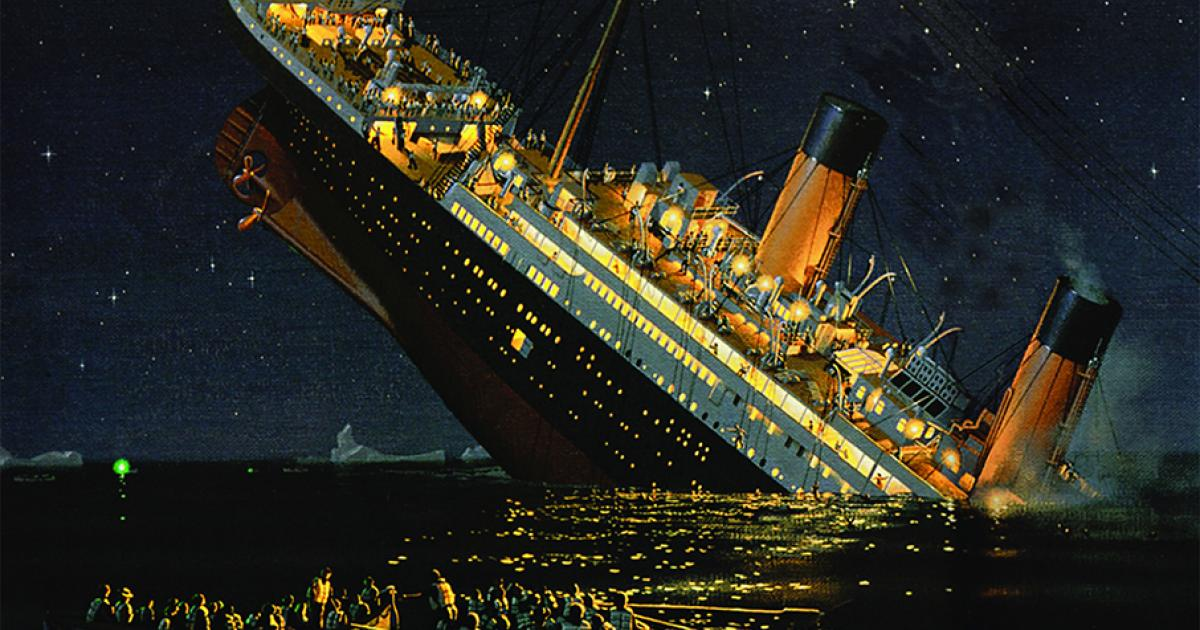

# Business Understanding
- Die Titanic ist im Jahr 1912 gesunken. Viele Menschen sind gestorben.

Problem:
- Nicht alle Passagiere hatten die gleichen Chancen zu überleben

Aufgabe:
- Herausfinden welche Faktoren über Leben und Tod entschieden haben.


### Ziel am Ende ist ein funktionierendes Modell dass Vorhersagen trifft wer Überlebt und Nicht Überlebt (Klassifikationsaufgabe).

- Eventuell auch eine Regressionsaufgabe wie Ticketpreis vorhersagen


# Data Understanding

Wir wollen den Datensatz untersuchen und verstehen

Wie bekommen wir einen Überblik über den Datensatz?



Ein DataFrame ist eine zweidimensionale Datenstruktur, also Daten die in Tabellen gespeichert sind mit Zeilen und Spalten.
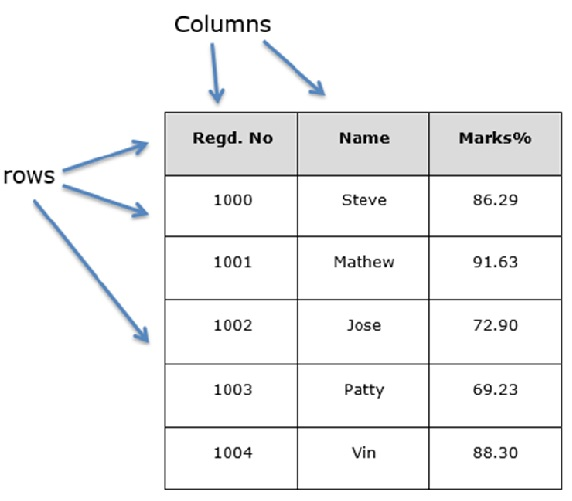

Ein Basis DataFrame ist ein leeres DataFrame

In [149]:
import pandas as pd
import numpy as np

df = pd.DataFrame() # Erstellt das DataFrame, noch leer, da nix in Klammer steht
df

In [150]:
# DatenFrame Dimension
df.shape

Der DataFrame kann auch mithilfe einer einzelnen Liste oder einer Liste von Listen erstellt werden

In [151]:
data = [1, 2, 3] # Deklariert der variable eine liste mit Werten, eckige Klammer bedeutet Liste
df = pd.DataFrame(data)
print(df.shape)
df

 Mit dem Parameter columns können die Namen der Spalten definiert werden.

In [152]:
data = [['Uwe', 30], ['Bobby', 19], ['Maria', 25]]# innere Listen sind Zeilen
df = pd.DataFrame(data, columns=['Name', 'Alter'],)
df

Aufgabe:
- Erstelle ein DataFrame mit 3 Spalten und 2 Zweilen.
- Die Spaltennnamen sind: Filmtitel, Genre, Bewertung (von 0-10)

In [ ]:
# Code deine Lösung


**Starten wir mit dem Titanic Datensatz**

In [154]:
df = pd.read_csv('https://raw.githubusercontent.com/nrfnm/linkit-grundlagenschulung/refs/heads/main/Titanic-Dataset.csv')

In [155]:
df.head()

PassengerId - PassengerID

Survived - 0=Tot, 1=Überlebt

Pclass - Ticket Klasse

Name - Vor und Nachname

Sex - Geschlecht

Age - Alter

SibSp - Anzahl Geschwister/Ehepartner

Parch - Anzahl Eltern/Kinder

Ticket - Ticket Nummer

Fare - Ticketpreis

Cabin - Kabinennummer

Embarked - Ort des Zustiegs

In [156]:
# Was sind die Spaltennamen?
df.columns

In [157]:
# Was sind die Dimensionen des Datensatzes
df.shape

In [158]:
df.info()

### Beachte die verschiedenen Datentypen
- PassengerId ist vom Typ integer --> eine ganze Zahl wie zum Beispiel 12
- Name ist vom Typ object --> ein Name wie zum Beispiel Jack
- Fare ist vom Typ float --> eine Dezimalzahl wie zum Beispiel 5.5




### Einfache Statistik fürs Verständnis

In [159]:
# Numpy verwenden

a = np.mean(df['Fare'])
b = np.median(df['Fare'])
c = np.min(df['Fare'])
d = np.max(df['Fare'])

# Das ist ein f-String. immer mit f"... {Variable}". --> Flexibel für Formattierungen
# \n bedeutet Zeilenumbruch, macht Output lesbarer

print(f"Durchschnittlicher Ticketpreis: {a}\n"
      f"Mittelwert Ticketpreis: {b:.2f}\n"
      f"Minimum Ticketpreis: {c}\n"
      f"Maximum Ticketpreis: {d:.2f}")


**Aufgabe**: Wie alt ist die jüngste und älteste Person? Runde auf 1 Nachkommastellen und printe das Ergebnis nicht in die Selbe Linie

In [ ]:
# Code deine Lösung


In [161]:
df.describe()

### Zeilen und Spalten umbenennen

Spalten umbenennen (mit "columns") und Zeilen umbenennen(mit "index)

In [162]:
df.rename(index = {0:'a', 1:'b', 2:'c'},
          columns = {'Pclass':'PassengerClass'}, inplace=True)

df.head()

### Neuordnung von Elementen
Wir werden paar Zeilen des Datensatzes neu ordnen. Dafür deklarieren wir eine neue Variable df2




In [163]:
df2 = pd.DataFrame(df, index = ['b', 'c', 'a'])
df2

Aufgabe:
- Benenne die Zeilen a,b,c jeweils in 0,1,2 um.
- Benenne die Spalte SibSp in SiblingSpouse um, und die Spalte Parch in ParentChildren um

In [ ]:
# Code deine Lösung


## Slicing
Hinweis: Die Zeilen werden beginnend mit 0 indiziert; die erste indizierte Zeile ist enthalten, die letzte hingegen ausgeschlossen.

In [165]:
# Beispiel: Slice out Passagier 1-5
df[0:5]

Aufgabe: Slice out Passagier 2-4

In [ ]:
# Code deine Lösung


Slice mit Namen indem man den Parameter **loc** benutzt

In [167]:
df.loc[:, ['Sex', 'Age']]

Slice mit Index indem man den Parameter **iloc** benutzt

In [168]:
df.iloc[3, :]

 Slice out bestimmte Spalten oder Zeilen mit iloc

In [169]:
df.iloc[[0, 3], [1, 2]]

In [170]:
df.head()

Aufgabe

In [ ]:
# Code deine lösung

# Slice out die erste Zeile durch Index (iloc)



In [ ]:
# Slice out alle Zeilen und die erste und letzte Spalte durch Index

In [ ]:
# Slice out die erste und letzte Zeile, sowie erste und letzte Spalte, durch Index


## Filtern

In [172]:
df['Fare'] > 200

In [173]:
df[df['Fare'] > 200]

In [174]:
df[df['Age'] == 49]

In [175]:
# Filter kombinieren

df[(df['Fare'] > 200) & (df['Sex'] == 'female')]

In [176]:
# Neue Spalte erstellen

df['IsAdult'] = df['Age'] >= 18
df.head()

In [177]:
# Numpy np.where benutzen
# Vorteil ist Lesbarkeit und Geschwindigkeit

df['IsAdult'] = np.where(df['Age'] >= 18, 'Adult', 'Child')
df.head()

In [178]:
# Spalte löschen

df = df.drop('IsAdult', axis=1) # axis=0 für Zeile, axis=1 für Spalte
df.head()

In [179]:
# Zeile hinzufügen
df.loc[len(df)] = {
    'PassengerId': 892,
    'Survived': 1,
    'PassengerClass': 3,
    'Name': 'Bauer, Thomas',
    'Sex': 'male',
    'Age': 26,
    'SiblingSpouse': 0,
    'ParentChildren': 2,
    'Ticket': 'PC 599',
    'Fare': 45.3279,
    'Cabin':np.nan,
    'Embarked': 'S'
}

In [180]:
df.tail()

In [181]:
# Zeile löschen
df = df.drop(891)
df.tail()

## Exploratory Data Analysis (EDA)
Wir prüfen Hypothesen, die man vom Film kennt
- "Frauen und Kinder zuerst!" (Geschlecht & Alter)
- "Geld regiert die Welt!" (Klasse, Fare)

In [182]:
import matplotlib.pyplot as plt # module zum plotten
import seaborn as sns
%config InlineBackend.figure_format = 'retina' # Schärfere Plots für retina displays

plt.figure(figsize=(10, 6)) # Rahmen mit bestimmter Größe für den Plot erstellen

# countplot = Zähle, wie oft etwas vorkommt
# data=df: unsere titanic csv df als Datenquelle nutzen
# x definiert x achsenwert, y definiert y achsenwert
# hue = einfärben nach survived/not survived
# palette = Farbschema
sns.countplot(data=df, x='Sex', hue='Survived', palette='viridis')

plt.title("Überleben nach Geschlecht")
plt.xlabel("Geschlecht")
plt.ylabel("Anzahl Passagiere")
plt.legend(title="Überlebt?", labels=['Nein (0)', 'Ja (1)'])
plt.show()

### --> Frauen hatten gute Chancen zu überleben und Männer geringe Chancen.

**Hatten Kinder (unter 18) insgesamt bessere Chancen zu überleben?**
- Erstelle eine Spalte namens "ChildAdult" die die Werte 'Child'(< 18) und 'Adult'(>= 18) beinhaltet
- Plotte das Ergebnis

Tipp: Nutze numpys np.where() Funktion zum Spalte erstellen

In [ ]:
# Code deine Lösung
# Erstelle die Spalte "ChildAdult" mit den oben genannten Werten


In [ ]:
# Code deine Lösung
# Plotte das Ergebnis, Überleben: Children vs. Adults


### --> Frauen und Kinder zuerst bestätigt sich da beide Klassen höhere Überlebenschancen hatten

### Bestätigt sich auch die zweite Hypothese "Geld regiert die Welt"?

In [185]:
plt.figure(figsize=(8, 6))

# Boxplot: x=Target (Survived), y=Continuous Variable (Fare)
# Er zeigt den Median und die Quartile der Preise für jede Gruppe.
sns.boxplot(data=df, x='Survived', y='Fare', hue='Survived', palette='viridis', showfliers = False)

plt.title('Ticketpreis-Verteilung Überlebt/Gestorben')
plt.xlabel('Überlebt?')
plt.ylabel('Ticketpreis')
plt.xticks(ticks=[0, 1], labels=['Gestorben (0)', 'Überlebt (1)']) # Labels klarer machen
plt.show()

### --> Median Ticketpreis der Überlebenden ist deutlich höher als der Median der Gestorbenen
- Mittellinie bei Gestorbenen bei 10 Dollar Überlebt hingegen bei 20-30 Dollar

## Geld regiert in der Tat die Welt

## Schauen wir uns noch an ob eine bessere Passagierklasse mehr Überlebende hatte

In [186]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='PassengerClass', hue='Survived', palette='viridis')

plt.title('Überleben nach Passagierklasse')
plt.xlabel('Ticket Klasse (1 = Höchste, 3 = Niedrigste)')
plt.ylabel('Anzahl Passagiere')
plt.legend(title='Überlebt?', labels=['Nein (0)', 'Ja (1)'])
plt.show()

## --> Klasse 1 hat eine deutlich höhere Überlebensrate als Klasse 3

# Data Preparation

**Daten bereinigen und transformieren:** Konkret bedeutet das:
- Missing values zu entfernen/ersetzen, doppelte Einträge entfernen, Ausreißer behandeln
- Daten in ein sauberes, numerisches Format umwandeln damit das Modell später die Daten verstehen und verarbeiten kann

### 1. Missing Values behandeln

In [187]:
missing_values = df.isnull().sum() # isnull() markiert alle leeren Zeilen als True, sum() zählt all diese Werte pro Spalte, wie viel missungvalues im dazensatz?

plt.figure(figsize=(10, 6))
sns.barplot(x=missing_values.index, y=missing_values.values)
plt.title('Anzahl der missing values pro Spalte')
plt.xlabel('Spalten')
plt.ylabel('Anzahl der missing values')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [188]:
# Checken welche Spalten missing values haben, auch ncoh in embarked
df.isnull().any()

In [189]:
print(f"Age missing: {(df['Age'].isnull().sum() / len(df)) * 100:.2f}%\n"
      f"Cabin missing: {(df['Cabin'].isnull().sum() / len(df)) * 100:.2f}%\n"
      f"Embarked mising: {(df['Embarked'].isnull().sum() / len(df)) * 100:.2f}%")

Schauen wir uns zuerst 'Cabin' an da es mit Abstand die meisten fehlenden Werte hat

In [190]:
df['Cabin'].values # alle nan missing values, amcht es Sinn zu ersetzen mit einer Kabine zu ersetzen die mit 80% vorkommt, hier nicht der Fall, viele unique

In [191]:
# Macht es Sinn mit mode zu ersetzen (most frequent value)?
print("Number of unique cabins:", df['Cabin'].nunique()) # nunique() counts number of unique values
print("Frequency of most booked cabin/s:", df['Cabin'].value_counts()) # value_counts() returns a series containing counts of unique values

### --> Die am häufigsten gebuchten Kabinen (z.B. G6, C23) kommen nur 3- bis 4-mal vor
- Wenn wir einfach mit mode imputieren (NaNs ersetzen) würden wäre das reines Raten und bringt dem Modell keinen Mehrwert

### --> Da 77% der Daten fehlen und keine sinnvolle Imputationsstrategie existiert, löschen wir die Spalte 'Cabin'

In [192]:
df = df.drop(columns=['Cabin'], axis=1)
df.head()

In [193]:
df.isnull().sum()

Wir haben noch ca. 20% missing values in der Spalte 'Age'. Schauen wir uns das genauer an

In [194]:
median_age = df['Age'].median()
mean_age = df['Age'].mean()

plt.figure(figsize=(10, 6))
sns.kdeplot(data=df, x='Age',fill=True, label="Altersverteilung") # kdeplot zecihnet eine weiche Kurve, geeignet um Verteilungen anzuschauen

# axvline = Zeichnet eine vertikale Linie
plt.axvline(median_age, color='green', linestyle='--', label=f'Median: {median_age:.0f}')
plt.axvline(mean_age, color='red', linestyle='-', label=f'Mittelwert: {mean_age:.0f}')

plt.title('Altersverteilung der Passagiere')
plt.xlabel('Alter')
plt.legend()
plt.show()

### --> Mittelwert ist leicht größer als Median. Liegt wahrscheinlich an wenigen älteren Passagieren.

### Next step: Wir wählen den Median um die NaNs zu ersetzen, da er robuster gegen Ausreißer ist

In [195]:
df['Age'] = df['Age'].fillna(median_age) # Die Funktion fillna() um NaNs zu ersetzen # Mediian nicht so beeinflusst on ausreißern, Median da hin, wo kein wert
df.isnull().sum()

**Zuletzt schauen wir uns 'Embarked' an**

Aufgabe: Plotte embarked mit einem Plot deiner Wahl und entscheide was wir mit den missing values machen

In [196]:
# Code deine Lösung
plt.figure(figsize=(10,6)) # Bild 20:22
sns.countplot(data=df, x='Embarked', hue='Embarked', palette='viridis')

plt.title('Häufigkeit der Häfen')
plt.xlabel('Hafen')
plt.ylabel('Anzahl Passagiere')

plt.show()

### --> Wir imputieren mit mode!

In [197]:
mode_embarked = df['Embarked'].mode()[0] # checken    # nur zwei dei fehlen, einafch zu höchsten, juckt net
df['Embarked'] = df['Embarked'].fillna(mode_embarked)
df.isnull().sum()

### Nach duplicates checken, in meisten Fällen wie hier wenn vorhanden droppen

In [198]:
df.duplicated().sum() # keine hier

### Was ist mit Ausreißern im Datensatz?

Schauen wir uns doch einfach die Ticketpreise an

In [199]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, y='Fare')

plt.title('Ticketpreis-Verteilung')
plt.show()

Die einzelnen schwarzen Kringel sind laut Boxplot Ausreißer.

Was glaubt ihr sollen wir die löschen, weil die nicht normal sind? Vorschläge

Wir gehen von aus, das alles wirklich so, nix löschen, Modell kann Außreißer nutzen, interpretieren, Ticketpreise wichtig im Zusammenhang, extreme Preisschwankungen wichtig für Modell zum Lernen, z.B. front detection: Manchmal genau des des wichtige

## Feature Engineering - Wir machen die Daten maschinenlesbar!





### Was ist Encoding?

In [200]:
import matplotlib.pyplot as plt

def plot_encoding_explanation():
    fig, ax = plt.subplots(figsize=(12, 5))

    # Achsen verstecken
    ax.axis('off')

    # 1. Box: Rohdaten (Text)
    ax.text(0.1, 0.6,
            "Daten (Mensch)\n\n'male'\n'female'\n'Southampton'",
            size=15, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.5", fc="#ffcccc", ec="red"))

    # 2. Pfeil: Encoding Prozess
    ax.annotate("Encoding\n(Übersetzer)",
                xy=(0.5, 0.6), xytext=(0.25, 0.6),
                arrowprops=dict(arrowstyle="->", lw=3, color="gray"),
                fontsize=12, ha="center")

    # 3. Box: Encoded Daten (Zahlen)
    ax.text(0.65, 0.6,
            "Daten (Maschine)\n\n0\n1\n2",
            size=15, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.5", fc="#ccffcc", ec="green"))

    # 4. Formel (Warum?)
    ax.text(0.65, 0.2,
            "Nur hiermit kann\nder Computer rechnen:\n\nFormel = 1 * Gewicht + 2",
            size=12, ha="center", va="center", style='italic')

    # Verbindung zur Formel
    ax.annotate("",
                xy=(0.65, 0.35), xytext=(0.65, 0.45),
                arrowprops=dict(arrowstyle="->", lw=2, color="green"))

    plt.title("Warum wir Encoding brauchen: Text vs. Mathe", fontsize=18)
    plt.show()

plot_encoding_explanation()

In [201]:
df.head()

### Längerer Name = Höhere Überlebenschance ?
Gedanke:
- Lange Namen zu der Zeit bedeutete vllt wichtige/reiche Personen
- verheiratete Frauen haben langen Namen, und Frauen überlebten oft

In [202]:
df['NameLength'] = df['Name'].apply(len) # .apply(len) misst Länge jeder Zeile , neue Spalte

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Survived', y='NameLength', hue = 'Survived', palette='viridis')

plt.title('Länge des Namens vs. Überleben')
plt.xlabel('Überlebt? (0 = Nein, 1 = Ja)')
plt.ylabel('Anzahl Buchstaben im Namen')
plt.show()

### --> Leute mit langem Namen haben häufiger überlebt

In [203]:
df.head()

#### Löschen wir Spalten die dem Modell keine relevanten Informationen geben

In [204]:
cols_to_drop = ['Name', 'Ticket', 'PassengerId']
df = df.drop(columns=cols_to_drop, axis=1)

In [205]:
df.head()

### Label-Encoding der Spalten 'Sex' in {0, 1} und 'ChildAdult' in {0, 1}
- Wir benutzen map() Funktion um in dem Fall Text in Zahlen umzuwandeln

In [206]:
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
df['ChildAdult'] = df['ChildAdult'].map({'Adult': 0, 'Child': 1})

### One-Hot Encoding der Spalte 'Embarked'
- pd.get_dummies erledigt das One-Hot Encoding. Macht aus der Spalte automatisch neue "Schalter-Spalten" mit Werten {0, 1}

In [207]:
df = pd.get_dummies(df, columns=['Embarked'], dtype=int) #1 da wo hinzugestiegen, 2 mal 0 wo nicht

In [208]:
df.head()

### --> Alle Werte sind in Zahlen umgewandelt, jetzt teilen wir unsere Daten in Training und Test Set auf

# Modeling

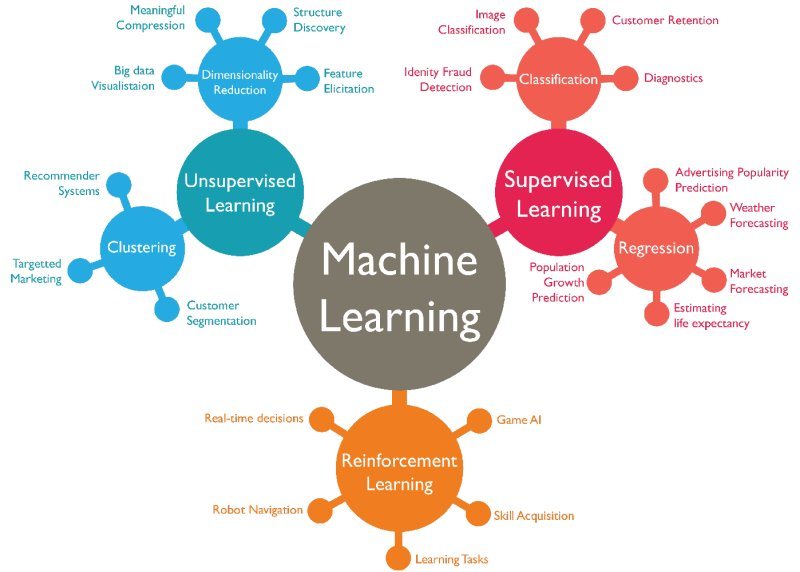

In [209]:
from sklearn.model_selection import train_test_split      # weclhes Modell eigent sich um Survides/not Survides? Logistsiche Klassikaikation gut
                                     # Daten aufsplitten trainieren, testen, andere Daten!!
# Definiere die Merkmalsvariable # alle Splaten außer Survived, des wollem wir ja vorhersagen, also Zielvariable
X = df.drop('Survived', axis=1)

# Definiere die Zielvariable
y = df['Survived']

# Train-Test-Split, test_size legt fest wieviele Daten ganz am Schluss einmalig benutzt werden um das Modell zu prüfen # 20% als y zum Testen
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) #random_state sorgt dafür dass wir immer gleiche Aufteilung bekommen

In [210]:
from sklearn.preprocessing import StandardScaler # Problem für Logsitsiche Regession, Alter geht von 0-100 und Preise nis 500, Modell denkt hohe Werte wichtig, wir wollen geliche Skalierung, für gelich wichtuge behandlung

# Scaler initialisieren
scaler = StandardScaler()

# Scaler auf Trainingsdaten anwenden. Syntaxerklärung: fit--> lernt wie die Daten aussehen (Mean, Std),
# transform--> scaler nimmt gelerten Werte und rechnet die Zahlen um
X_train_scaled = scaler.fit_transform(X_train)

# Scaler auf Testdaten anwenden. ACHTUNG: nur .transform und nicht transform.fit.
# Ansonsten --> DATA LEAKAGE(DATENLECK), ist sehr schlecht!! Wir wollen ja so tun, als kennten wir die Testdaten noch nicht, sonst sieht Modell Testdaten schon !!!
X_test_scaled = scaler.transform(X_test)

# Logistische Regression

- Binäres Problem: Genau 2 Ausgänge (0 -> not survived, oder 1 -> survived). --> Ideal für Logistische Regression

- Erklärbarkeit (White Box):

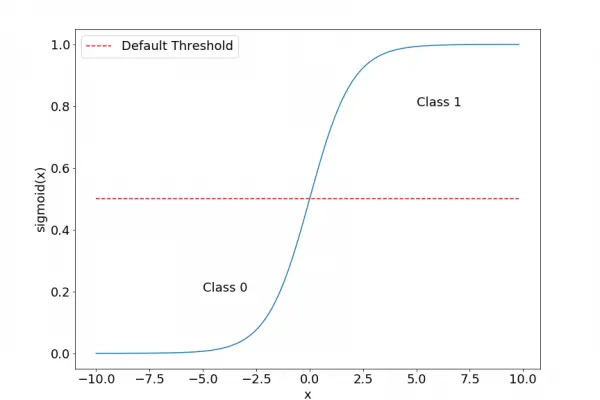

Ein Punkt auf der X-Achse ist quasi der "Gesamteindruck", den das Modell von einer Person hat, basierend auf allen gesammelten Features gleichzeitig.

In [211]:
from sklearn.linear_model import LogisticRegression # die nächsten paar checken

# Logistische Regression initialisieren
logr_model = LogisticRegression()

# Modell trainieren
logr_model.fit(X_train_scaled, y_train)

# Evaluation

In [212]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Vorhersage auf den Testdaten machen
y_pred = logr_model.predict(X_test_scaled)

# Accuracy sagt uns wie genau ist unser Modell, also wie oft liegt es insgesamt richtig.
accuracy = accuracy_score(y_test, y_pred)

print(f"Das Modell hat eine Accuracy von: {accuracy:.2%}")

### Achtung: Accuracy für die Modellperformance kann bei Class Imbalance in die Irre führen!

In [213]:
df['Survived'].value_counts()

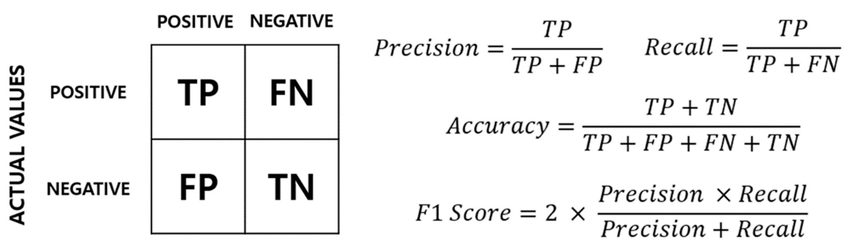

- Accuracy:	"Wie viele Schicksale haben wir korrekt vorhergesagt?"
- Precision:	"Wenn wir 'Überlebt' sagen – stimmt das auch? (Vermeidung von falschem Optimismus)"
- Recall:	"Haben wir alle Überlebenden gefunden? (Vermeidung von Übersehenen)"
- F1-Score:	"Der Kompromiss: Wir wollen niemanden übersehen, aber auch nicht jeden wild als Überlebenden raten."

In [214]:
# Weitere Metriken zur Evaluation des Modells

# Detaillierter Bericht (Präzision, Recall, F1-Score)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Konfusionsmatrix visualisieren (Was wurde richtig/falsch klassifiziert?)
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Vorhergesagt')
plt.ylabel('Tatsächlich')
plt.show()          # recall interessant, wie veil von denen tatsächlich übelrebt ahben wir vorhergesagt , wir 24% sterebn lassen, nur 76% passen, f1 mischung recall, precision, prescion: von allen Überlbt ,wie viel atatsähclih wahr? vermiedne von Suchen leuten, die tot, insgemsgt ok echt

### Fazit:
- Wenn es Überlebende Passagiere vorhersagt, hat es zu 77% Recht (Precision).
- Aber es übersieht leider auch 24% der Leute, die eigentlich hätten gerettet werden können (Recall = 76%).
- Insgesamt versteht es die Situation zu 80% (Accuracy).

### ROC (Receiver Operating Characteristic) und Feature Importance

Da wir viele Dimensionen haben (Alter, Klasse, Geschlecht...), können wir keine einfache 2D-Linie durch die Punkte zeichnen. Stattdessen schauen wir uns zwei Dinge an:

- ROC Kurve: Sie zeigt, wie gut das Modell survived von not survived trennt. Je größer die Fläche unter der Kurve (AUC), desto besser.
- Gewichte: Sie zeigen, welche Features wichtig waren.

In [215]:
import matplotlib.pyplot as plt     # ideal für blau wäre eck bei 1, 2. PLOT NIMMT nur 1. wert Spalte, also Frau da 1, posiitvi, 3 Klasse schlecht, höheres Alter schlecht
import seaborn as sns
from sklearn.metrics import roc_curve, roc_auc_score

# --- PLOT 1: ROC Kurve (Performance Visualisierung) ---
# Wir brauchen die Wahrscheinlichkeiten, nicht nur 0/1 (daher predict_proba)
y_pred_proba = logr_model.predict_proba(X_test_scaled)[:, 1]

# Berechnung der Kurve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
auc_score = roc_auc_score(y_test, y_pred_proba)

plt.figure(figsize=(12, 5))

# Plot ROC
plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, label=f'Logistische Regression (AUC = {auc_score:.2f})', color='blue')
plt.plot([0, 1], [0, 1], 'r--', label='Zufall (Raten)') # Diagonale Linie (Raten)
plt.xlabel('False-Positive-Rate')
plt.ylabel('True-Positive-Rate')
plt.title('ROC Kurve (Je näher an der Ecke links oben, desto besser)')
plt.legend()
plt.grid(True)


# --- PLOT 2: Feature Importance (Erklärbarkeit) ---
# Wir holen uns die Gewichte (Koeffizienten) aus dem Modell
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Gewicht': logr_model.coef_[0]
})
# Sortieren für schönere Darstellung
coefficients = coefficients.sort_values(by='Gewicht', ascending=False)

# Plot Coefficients
plt.subplot(1, 2, 2)
sns.barplot(x='Gewicht', y='Feature', data=coefficients, hue = 'Gewicht', palette='viridis_r')
plt.title('Einfluss der Features auf das Überleben\n(Positiv = Gut für Überleben, Negativ = Schlecht)')
plt.axvline(x=0, color='black', linestyle='--') # Nulllinie
plt.tight_layout()
plt.show()

### Linker Plot erklärt
- Rote Linie: Raten wer überlebt zum Beispiel Münze werfen)
- Blaue Linie: Je größer die Fläche drunter desto besser das Modell, --> 89% ist gute Trennschärfe


### Rechter Plot erklärt
Das Modell stellt sich bei jedem Balken nur eine Frage:

"Wenn die Zahl in dieser Spalte HÖHER wird, steigt dann die Wahrscheinlichkeit zu überleben?"

JA → Balken nach Rechts (Grün).

NEIN → Balken nach Links (Lila).



# Random Forest Classifier

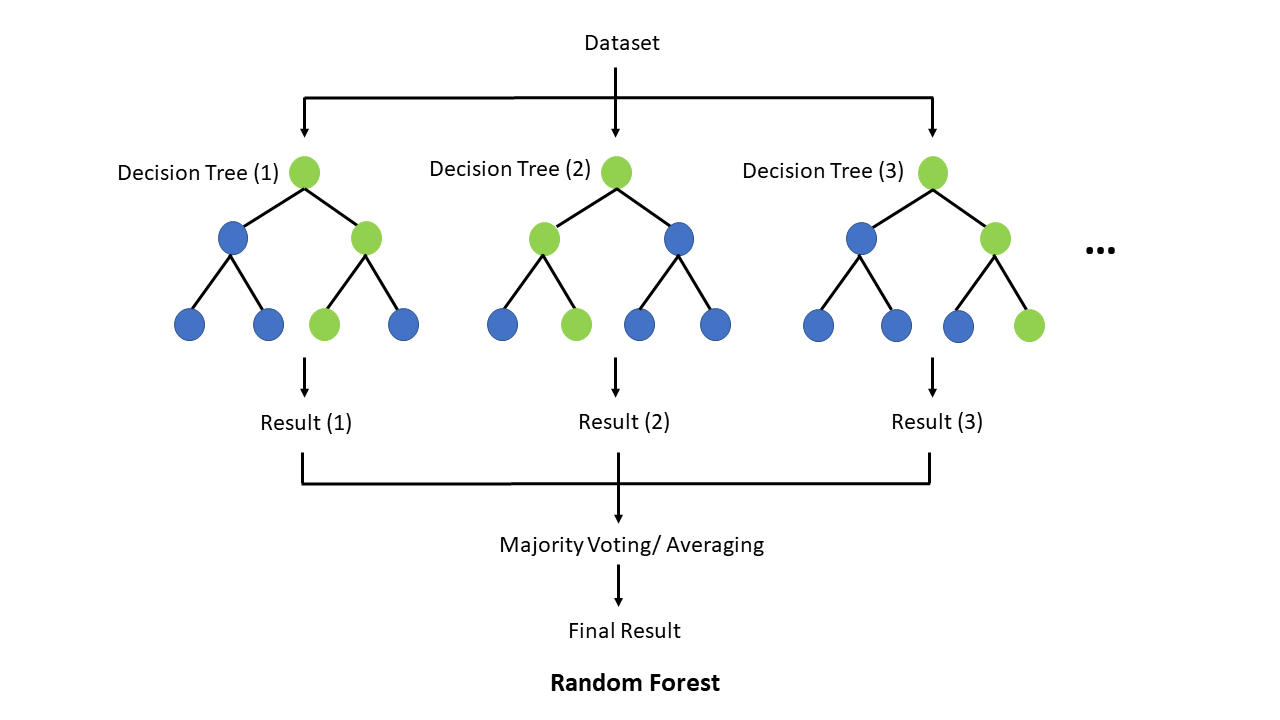

### Wie funktioniert ein Random Forest?
- Ensemble Learning: Statt einen Etscheidungsbaum trainieren wir mehrere Entscheidungsbäume --> geben robusteres Ergebnis und robuster gegen Overfitting
- Bagging (Bootstrap Aggregation): Trainieren z.B. 100 EBs parallel. Aber jeder Baum bekommt zum Lernen einen zufälligen Teil der Daten (ziehen mit zurücklegen)
- Feature Randomness: Jeder Baum bekommt zufällige Features (z.B. sieht Baum A nur „Age & Fare“, Baum B nur „Sex & PClass“).
- Majority Voting: Am Ende zählt die Mehrheit. Wenn 70 Bäume sagen „Überlebt“ und 30 sagen „Nicht überlebt“, ist das Ergebnis: Überlebt. Wichtig: gegen Oversitting, nicht auswendiglernen, random forest ist robust dagegen,
jeder bekommt zufällige Daten, ganz zufällig, Variatin an daten in jedem Baum , robust, und zufällige features/Merkmalsvariablen


In [216]:
# Code deine Lösung:
# importiere das Modul für RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier
# intialisiere das Modell mit folgenden parametern: anzahl der bäume ist 100, random state ist 42
rf_model =  RandomForestClassifier(n_estimators=100, random_state=42)

# trainiere das Modell
rf_model.fit(X_train, y_train) # random forest egal ob skaliert, man muss nicht X_train scaled
# Das bleibt unverändert
print(f"Training fertig! Das Modell hat von {len(X_train)} Passagieren gelernt.")

In [217]:
# Code deine Lösung:
# mache die Vorhersagen (y_pred)
y_pred = rf_model.predict(X_test)
# printe die accuracy Metrik auf 2 Nachkommastellen aus
accuracy = accuracy_score(y_test, y_pred)


print(f"Das Modell hat eine Accuracy von: {accuracy:.2%}")

In [218]:
# Weitere Metriken zur Evaluation des Modells

# Detaillierter Bericht (Präzision, Recall, F1-Score)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Konfusionsmatrix visualisieren (Was wurde richtig/falsch klassifiziert?)
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Vorhergesagt')
plt.ylabel('Tatsächlich')
plt.show()

Classification Report Logistische Regression:

               precision    recall  f1-score   support

           0       0.83      0.84      0.83       105
           1       0.77      0.76      0.76        74

    accuracy                           0.80       179
   

Classification Report Random Forest: löst. das Problem besser

               precision    recall  f1-score   support

           0       0.86      0.90      0.88       105
           1       0.84      0.80      0.82        74

    accuracy                           0.85       179
     

In [219]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Wahrscheinlichkeiten holen
y_pred_proba_log = logr_model.predict_proba(X_test_scaled)[:, 1]
y_pred_proba_rf = rf_model.predict_proba(X_test)[:, 1] # RF braucht oft keine skalierten Daten, aber check deine Pipeline

# 2. Scores berechnen
auc_log = roc_auc_score(y_test, y_pred_proba_log)
auc_rf = roc_auc_score(y_test, y_pred_proba_rf)

# 3. Kurven berechnen
fpr_log, tpr_log, _ = roc_curve(y_test, y_pred_proba_log)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)

# 4. Plotten
plt.figure(figsize=(10, 6))
plt.plot(fpr_log, tpr_log, label=f'Logistische Reg. (AUC = {auc_log:.2f})', linestyle='--')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.2f})', color='green', linewidth=2)
plt.plot([0, 1], [0, 1], 'r--', label='Zufall')

plt.title('Random Forest vs. Logistic Regression')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

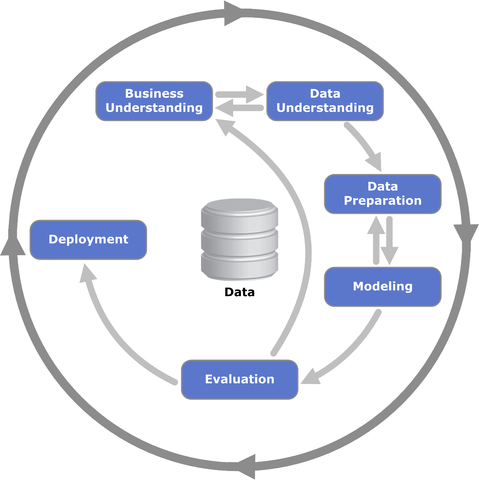

# Deployment

## Szenario: Das interaktive Museumsterminal

Wir bauen eine App für ein Titanic-Museum. Besucher geben am Eingang ihre Daten ein (Alter, Geschlecht, Ticketklasse).

Beispiel Input: "Ich bin 30 Jahre alt, männlich, 3. Klasse."

Das Modell (im Hintergrund): Berechnet die Wahrscheinlichkeit.

Output auf dem Bildschirm: "Leider hättest du wahrscheinlich nicht überlebt (Wahrscheinlichkeit fürs Überleben: 12%)." oder "Glückwunsch! Du hättest einen Platz im Rettungsboot bekommen."

### Wir simuliere das in einem Web Server

### Schritt 1: Modell speichern

In [220]:
import joblib

# Speichert das Modell direkt in eine Datei (effizienter für NumPy)
joblib.dump(rf_model, 'titanic_model.pkl')

print("Modell erfolgreich mit Joblib gespeichert!")

### Schritt 2: Server einrichten

Hier nutzen wir Flask. Das ist ein Mini-Webserver für Python.



In [ ]:
from flask import Flask, request, jsonify
import numpy as np
"""
Die URL Argumente sind:
pclass = Ticket Klasse (1, 2, 3)
sex = Geschlecht ('male', 'female')
age = Alter (z.B. 22)

Das Modell braucht aber 11 Features. Wir füllen den Rest auf!
"""

app = Flask(__name__)

@app.route('/predict')
def predict():
    # 1. Inputs aus der URL holen
    pclass = int(request.args.get('pclass'))
    sex_str = request.args.get('sex')
    age = float(request.args.get('age'))

    # 2. Datenaufbereitung (Feature Engineering live)

    # Sex in Zahl umwandeln (male=0, female=1)
    sex_encoded = 1 if sex_str == 'female' else 0

    # Feature "ChildAdult" berechnen (wie im Training notebook)
    child_adult = 1 if age < 18 else 0

    # 3. Den Vektor bauen (Imputation der fehlenden Werte mit Durchschnitten)
    # Reihenfolge muss exakt wie im Training sein!
    # [Pclass, Sex, Age, SibSp, Parch, Fare, ChildAdult, NameLength, Emb_C, Emb_Q, Emb_S]

    features = [
        pclass,         # User Input
        sex_encoded,    # User Input (encoded)
        age,            # User Input
        0,              # Default: SibSp
        0,              # Default: Parch
        32.2,           # Default: Fare (Durchschnitt)
        child_adult,    # Berechnet: ChildAdult
        27,             # Default: NameLength
        0,              # Default: Emb_C
        0,              # Default: Emb_Q
        1               # Default: Emb_S (Southampton)
    ]

    # Load model
    try:
        model = joblib.load('titanic_model.pkl')
    except FileNotFoundError:
        return "Fehler: Bitte erst /train aufrufen, um das Modell zu speichern!"

    # Make prediction
    # Reshape für 1 einzelne Vorhersage (1 Zeile, 11 Spalten)
    prediction = model.predict([features])
    predicted_class = int(prediction[0])

    # Wahrscheinlichkeit holen (optional, aber cool)
    prob = model.predict_proba([features])[0][1]

    # Return Result
    return jsonify({
        'prediction': 'Survived' if predicted_class == 1 else 'Not Survived',
        'probability': f"{prob*100:.1f}%",
        'input_received': {
            'pclass': pclass,
            'sex': sex_str,
            'age': age,
            'is_child': bool(child_adult)
        }
    })

# --- 3. RUN ---
if __name__ == '__main__':
    # use_reloader=False ist wichtig in Jupyter Notebooks
    app.run(debug=True, use_reloader=False, host='0.0.0.0', port=8000)